# 03 — EDA và PCA trên CIFAR-10
**Mục tiêu:** bổ sung phần khám phá dữ liệu (EDA) và phân tích thành phần chính (PCA) cho Lab 2.

- **EDA:** kích thước, phân bố lớp, kiểm tra phép chia train/validation, thống kê pixel, độ sáng, ảnh trùng lặp, tác động của việc resize 32→224.
- **PCA:** phương sai giải thích, eigen-images, biểu diễn 2D, tái tạo ảnh, và baseline kNN trên không gian PCA.
- *(Tùy chọn)* So sánh PCA trên pixel thô với PCA trên đặc trưng DenseNet121 pre-trained.

> Notebook này **không ghi sẵn kết luận**. Mọi nhận xét điền vào các ô "Nhận xét sau khi chạy" sau khi bạn chạy và xem kết quả thật.

## 0. Thiết lập

In [3]:
import sys
print(sys.executable)

d:\learn_DeepLearning\Lab3\.venv311\Scripts\python.exe


In [4]:
!{sys.executable} -m pip install torchvision

  Using cached torchvision-0.29.2-py3-none-win_amd64.whl.metadata (5.7 kB)
Using cached torchvision-0.29.2-py3-none-win_amd64.whl (1.4 MB)



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import hashlib
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from torch.utils.data import random_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_DIR = Path("../data")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
SAVE_FIGS = True  # đặt False nếu không muốn ghi đè ảnh trong reports/figures

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406])
IMAGENET_STD = np.array([0.229, 0.224, 0.225])

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})


def save_fig(name):
    if SAVE_FIGS:
        plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")

In [6]:
# Dữ liệu thô (uint8, shape [N, 32, 32, 3]) — không qua transform để EDA phản ánh đúng dữ liệu gốc
train_ds = torchvision.datasets.CIFAR10(root=str(DATA_DIR), train=True, download=True)
test_ds = torchvision.datasets.CIFAR10(root=str(DATA_DIR), train=False, download=True)

X_train, y_train = train_ds.data, np.array(train_ds.targets)
X_test, y_test = test_ds.data, np.array(test_ds.targets)
classes = train_ds.classes
print("Các lớp:", classes)

Các lớp: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 1. EDA — Khám phá dữ liệu
### 1.1 Tổng quan kích thước và kiểu dữ liệu

In [7]:
overview = pd.DataFrame({
    "Tập": ["Train gốc", "Test"],
    "Số ảnh": [len(X_train), len(X_test)],
    "Shape": [X_train.shape, X_test.shape],
    "dtype": [X_train.dtype, X_test.dtype],
    "Min pixel": [X_train.min(), X_test.min()],
    "Max pixel": [X_train.max(), X_test.max()],
})
overview

,Tập,Số ảnh,Shape,dtype,Min pixel,Max pixel
0,Train gốc,50000,"(50000, 32, 32, 3)",uint8,0,255
1,Test,10000,"(10000, 32, 32, 3)",uint8,0,255


### 1.2 Phân bố số ảnh theo lớp

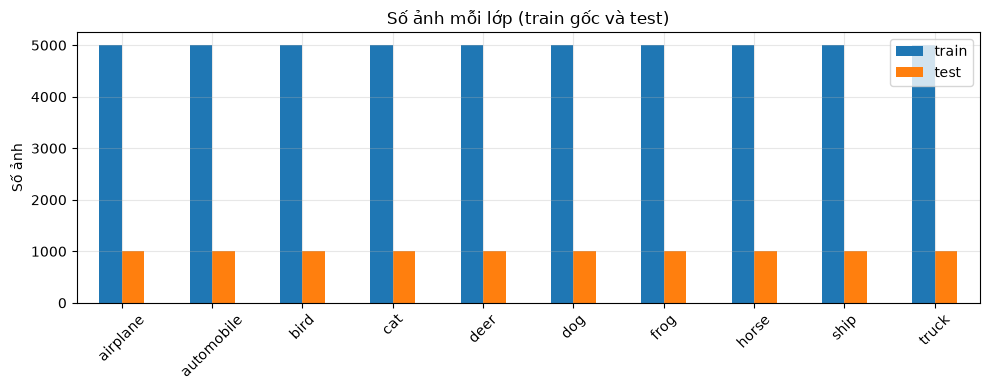

,train,test
airplane,5000,1000
automobile,5000,1000
bird,5000,1000
cat,5000,1000
deer,5000,1000
dog,5000,1000
frog,5000,1000
horse,5000,1000
ship,5000,1000
truck,5000,1000


In [8]:
dist = pd.DataFrame(
    {"train": np.bincount(y_train, minlength=10), "test": np.bincount(y_test, minlength=10)},
    index=classes,
)
ax = dist.plot(kind="bar", figsize=(10, 4))
ax.set_ylabel("Số ảnh")
ax.set_title("Số ảnh mỗi lớp (train gốc và test)")
plt.xticks(rotation=45)
plt.tight_layout()
save_fig("eda_class_distribution.png")
plt.show()
dist

### 1.3 Kiểm tra phép chia train / validation
Tái tạo đúng cách chia trong `src/data.py`: `random_split` với `val_ratio=0.1` và `torch.Generator().manual_seed(42)`.
Phép chia này **không phân tầng theo lớp**, nên số ảnh mỗi lớp trong validation có thể lệch nhẹ.

Train: 45000 | Validation: 5000 | Trùng nhau: 0


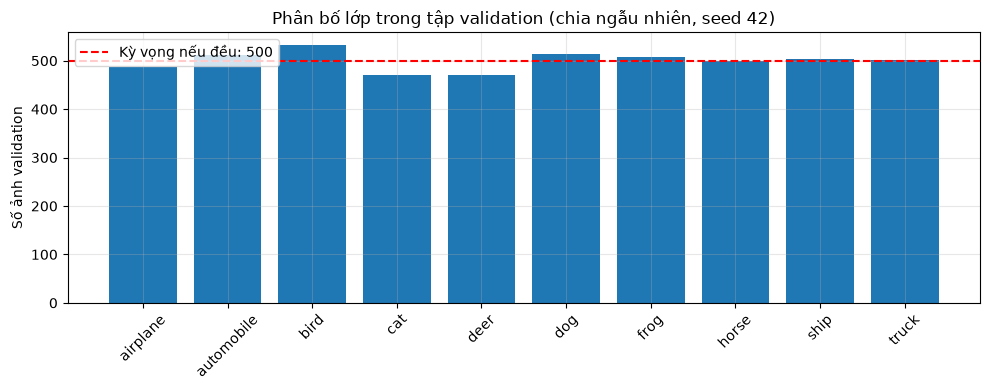

,train,val,val_share_%
airplane,4512,488,9.76
automobile,4488,512,10.24
bird,4468,532,10.64
cat,4529,471,9.42
deer,4529,471,9.42
dog,4486,514,10.28
frog,4493,507,10.14
horse,4500,500,10.00
ship,4496,504,10.08
truck,4499,501,10.02


In [9]:
val_size = int(len(X_train) * 0.1)
train_size = len(X_train) - val_size
generator = torch.Generator().manual_seed(SEED)
train_subset, val_subset = random_split(list(range(len(X_train))), [train_size, val_size], generator=generator)

train_idx = np.array(train_subset.indices)
val_idx = np.array(val_subset.indices)
print(f"Train: {len(train_idx)} | Validation: {len(val_idx)} | Trùng nhau: {len(set(train_idx) & set(val_idx))}")

split_dist = pd.DataFrame({
    "train": np.bincount(y_train[train_idx], minlength=10),
    "val": np.bincount(y_train[val_idx], minlength=10),
}, index=classes)
split_dist["val_share_%"] = (100 * split_dist["val"] / (split_dist["train"] + split_dist["val"])).round(2)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(classes, split_dist["val"])
ax.axhline(val_size / 10, color="red", linestyle="--", label=f"Kỳ vọng nếu đều: {val_size // 10}")
ax.set_ylabel("Số ảnh validation")
ax.set_title("Phân bố lớp trong tập validation (chia ngẫu nhiên, seed 42)")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
save_fig("eda_val_split_distribution.png")
plt.show()
split_dist

### 1.4 Ảnh mẫu theo từng lớp (8 ảnh ngẫu nhiên mỗi lớp)

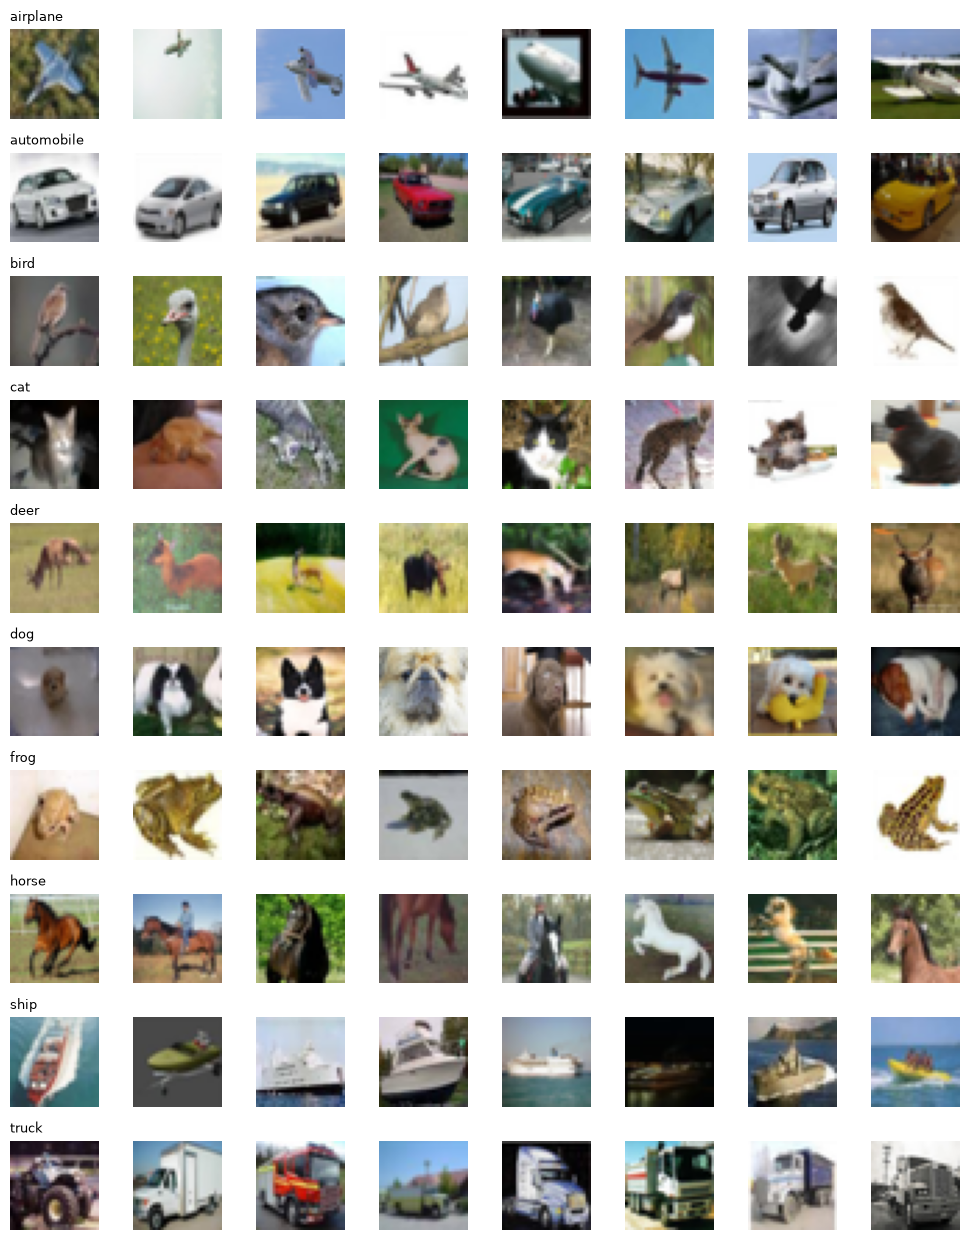

In [10]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(10, 8, figsize=(10, 12.5))
for c in range(10):
    chosen = rng.choice(np.where(y_train == c)[0], 8, replace=False)
    for j, i in enumerate(chosen):
        axes[c, j].imshow(X_train[i])
        axes[c, j].axis("off")
        if j == 0:
            axes[c, j].set_title(classes[c], loc="left", fontsize=9)
plt.tight_layout()
save_fig("eda_samples_per_class.png")
plt.show()

### 1.5 Thống kê pixel theo kênh màu
So sánh mean/std của CIFAR-10 với mean/std ImageNet mà pipeline đang dùng để normalize.

In [11]:
def channel_stats(X, chunk=5000):
    """Mean/std theo kênh RGB trong thang [0, 1], tính theo từng khối để tiết kiệm RAM."""
    n, s, s2 = 0, np.zeros(3), np.zeros(3)
    for i in range(0, len(X), chunk):
        b = X[i:i + chunk].astype(np.float64) / 255.0
        s += b.sum(axis=(0, 1, 2))
        s2 += (b ** 2).sum(axis=(0, 1, 2))
        n += b.shape[0] * b.shape[1] * b.shape[2]
    mean = s / n
    return mean, np.sqrt(s2 / n - mean ** 2)

train_mean, train_std = channel_stats(X_train)
test_mean, test_std = channel_stats(X_test)

stats = pd.DataFrame({
    "CIFAR train mean": train_mean, "CIFAR test mean": test_mean, "ImageNet mean": IMAGENET_MEAN,
    "CIFAR train std": train_std, "CIFAR test std": test_std, "ImageNet std": IMAGENET_STD,
}, index=["R", "G", "B"]).round(4)
stats

,CIFAR train mean,CIFAR test mean,ImageNet mean,CIFAR train std,CIFAR test std,ImageNet std
R,0.4914,0.4942,0.485,0.2470,0.2467,0.229
G,0.4822,0.4851,0.456,0.2435,0.2429,0.224
B,0.4465,0.4504,0.406,0.2616,0.2616,0.225


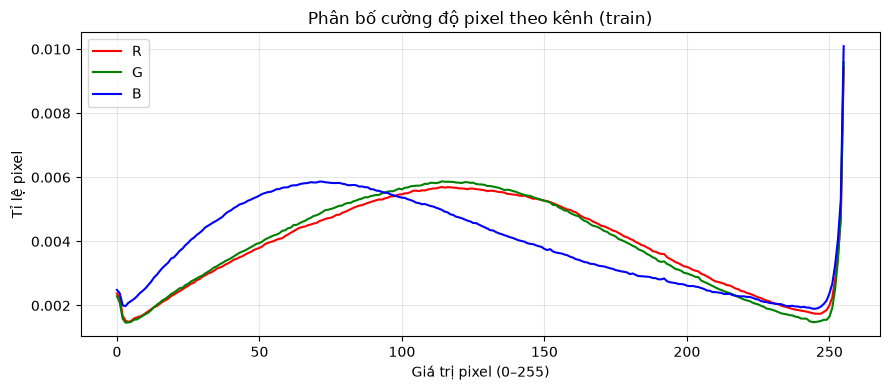

In [12]:
# Histogram cường độ pixel theo kênh (tính chính xác trên toàn bộ tập train)
fig, ax = plt.subplots(figsize=(9, 4))
for c, (color, name) in enumerate(zip(["red", "green", "blue"], ["R", "G", "B"])):
    counts = np.bincount(X_train[..., c].ravel(), minlength=256)
    ax.plot(counts / counts.sum(), color=color, label=name)
ax.set_xlabel("Giá trị pixel (0–255)")
ax.set_ylabel("Tỉ lệ pixel")
ax.set_title("Phân bố cường độ pixel theo kênh (train)")
ax.legend()
plt.tight_layout()
save_fig("eda_pixel_histogram.png")
plt.show()

### 1.6 Độ sáng và màu trung bình theo lớp

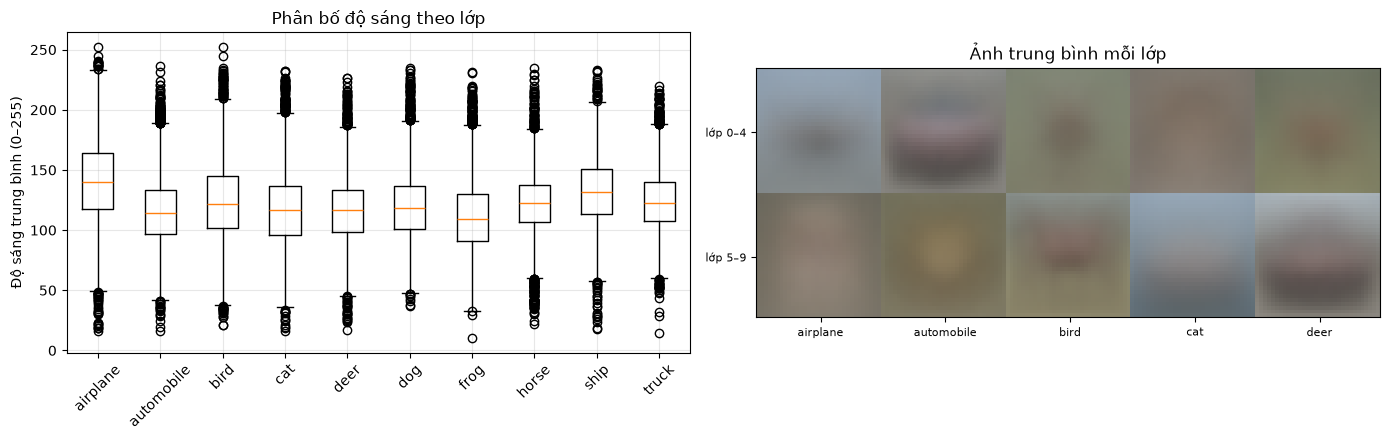

,R,G,B
lớp,,,
airplane,134.04,142.88,150.17
automobile,120.15,115.91,114.04
bird,124.76,125.33,108.13
cat,126.35,116.39,105.96
deer,120.26,118.63,96.44
dog,127.48,118.48,106.22
frog,119.86,111.79,88.03
horse,128.00,122.37,106.31
ship,125.01,133.98,141.44


In [13]:
rgb_mean = X_train.mean(axis=(1, 2))                       # [N, 3]
brightness = rgb_mean @ np.array([0.299, 0.587, 0.114])   # độ sáng (luma) mỗi ảnh

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].boxplot([brightness[y_train == c] for c in range(10)])
axes[0].set_xticks(range(1, 11))
axes[0].set_xticklabels(classes, rotation=45)
axes[0].set_ylabel("Độ sáng trung bình (0–255)")
axes[0].set_title("Phân bố độ sáng theo lớp")

# Ảnh trung bình của từng lớp
mean_imgs = np.stack([X_train[y_train == c].mean(axis=0) / 255.0 for c in range(10)])
canvas = np.concatenate([np.concatenate(list(mean_imgs[:5]), axis=1),
                         np.concatenate(list(mean_imgs[5:]), axis=1)], axis=0)
axes[1].imshow(np.clip(canvas, 0, 1))
axes[1].set_xticks([16 + 32 * i for i in range(5)])
axes[1].set_xticklabels(classes[:5], fontsize=8)
axes[1].set_yticks([16, 48])
axes[1].set_yticklabels(["lớp 0–4", "lớp 5–9"], fontsize=8)
axes[1].set_title("Ảnh trung bình mỗi lớp")
axes[1].grid(False)
plt.tight_layout()
save_fig("eda_brightness_mean_images.png")
plt.show()

per_class_rgb = pd.DataFrame(rgb_mean, columns=["R", "G", "B"])
per_class_rgb["lớp"] = [classes[i] for i in y_train]
per_class_rgb.groupby("lớp").mean().round(2)

### 1.7 Kiểm tra ảnh trùng lặp (khớp chính xác từng byte)

In [14]:
def image_hashes(X):
    return [hashlib.md5(img.tobytes()).hexdigest() for img in X]

h_train, h_test = image_hashes(X_train), image_hashes(X_test)
print(f"Ảnh trùng lặp bên trong train: {len(h_train) - len(set(h_train))}")
print(f"Ảnh trùng lặp bên trong test : {len(h_test) - len(set(h_test))}")
print(f"Ảnh xuất hiện ở cả train và test: {len(set(h_train) & set(h_test))}")

Ảnh trùng lặp bên trong train: 0
Ảnh trùng lặp bên trong test : 0
Ảnh xuất hiện ở cả train và test: 0


### 1.8 Tác động của việc resize 32×32 → 224×224
Pipeline phóng ảnh lên 224×224 để khớp đầu vào của VGG/DenseNet pre-trained. Ô này minh họa mức tăng dữ liệu cần xử lý — một yếu tố liên quan đến thời gian train dài khi chạy trên CPU.

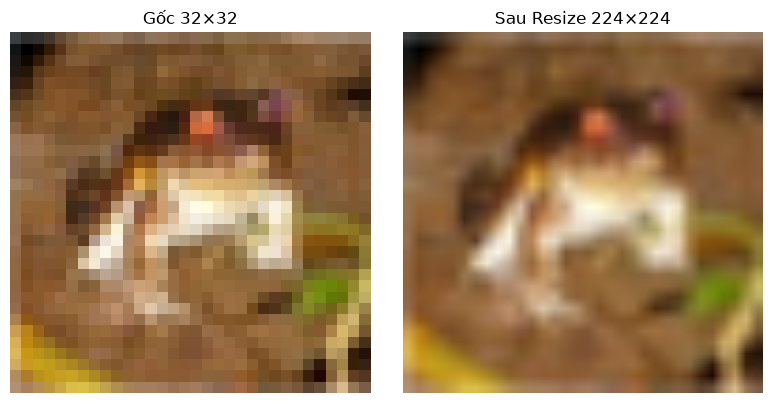

Số pixel tăng 49 lần
Bộ nhớ 1 ảnh float32: 12.0 KB (32×32) -> 588.0 KB (224×224)


In [15]:
from PIL import Image
from torchvision import transforms

i = 0
orig = Image.fromarray(X_train[i])
resized = transforms.Resize((224, 224))(orig)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(orig); axes[0].set_title("Gốc 32×32"); axes[0].axis("off")
axes[1].imshow(resized); axes[1].set_title("Sau Resize 224×224"); axes[1].axis("off")
plt.tight_layout()
save_fig("eda_resize_effect.png")
plt.show()

ratio = (224 * 224) / (32 * 32)
print(f"Số pixel tăng {ratio:.0f} lần")
print(f"Bộ nhớ 1 ảnh float32: {3 * 32 * 32 * 4 / 1024:.1f} KB (32×32) -> {3 * 224 * 224 * 4 / 1024:.1f} KB (224×224)")

### Nhận xét EDA sau khi chạy
- **Cân bằng lớp ở train/test:** Dữ liệu CIFAR-10 gốc hoàn toàn cân bằng lý tưởng. Tập Train gồm 50.000 ảnh chia đều cho 10 lớp (đúng 5.000 ảnh/lớp). Tập Test gồm 10.000 ảnh chia đều cho 10 lớp (đúng 1.000 ảnh/lớp). Không có hiện tượng mất cân bằng lớp (class imbalance).
- **Độ lệch số ảnh mỗi lớp trong validation so với kỳ vọng:** Phép chia `random_split` (10% validation = 5.000 ảnh, seed 42) không phân tầng (non-stratified) nên có độ lệch nhẹ so với kỳ vọng đều 500 ảnh/lớp (10.0%):
  - Lớp nhiều nhất: `bird` (532 ảnh, chiếm 10.64%, lệch +32 ảnh), `dog` (514 ảnh, 10.28%), `automobile` (512 ảnh, 10.24%).
  - Lớp ít nhất: `cat` (471 ảnh, chiếm 9.42%, lệch -29 ảnh), `deer` (471 ảnh, 9.42%), `airplane` (488 ảnh, 9.76%).
  - Các lớp khác sát mốc 500: `horse` (500), `truck` (501), `ship` (504), `frog` (507).
  - Độ lệch tối đa chỉ ±32 ảnh (~6.4% so với kỳ vọng), vẫn đảm bảo tính đại diện đồng đều của 10 lớp để chọn mô hình.
- **So sánh mean/std CIFAR-10 với ImageNet:**
  - CIFAR-10 Train Mean: R = 0.4914, G = 0.4822, B = 0.4465; Std: R = 0.2470, G = 0.2435, B = 0.2616.
  - CIFAR-10 Test Mean/Std gần như trùng khớp hoàn toàn với Train (Mean: [0.4942, 0.4851, 0.4504], Std: [0.2467, 0.2429, 0.2616]), chứng tỏ 2 tập cùng phân phối thống kê.
  - So với ImageNet chuẩn (Mean: [0.4850, 0.4560, 0.4060], Std: [0.2290, 0.2240, 0.2250]), CIFAR-10 có kênh G và B sáng hơn khoảng 0.026 - 0.040 (nhiều ảnh có bầu trời/biển) và độ phân tán màu rộng hơn nhẹ (~0.02 - 0.035). Việc dùng chuẩn ImageNet khi transfer learning là cần thiết để tương thích với pre-trained weights.
- **Lớp có độ sáng/màu đặc trưng:**
  - Sáng nhất: `airplane` (độ sáng trung bình 141.07; kênh B = 150.17 cao vượt trội do bầu trời xanh) và `ship` (132.15; kênh B = 141.44 do mặt nước biển).
  - Tối nhất: `frog` (độ sáng trung bình 111.50; kênh B thấp nhất = 88.03, nổi bật nền xanh lá/đầm lầy tối) và `deer` (116.59; kênh B = 96.44 do môi trường rừng cây).
  - Các lớp động vật (`cat`, `dog`, `bird`, `horse`) và xe cộ (`automobile`, `truck`) có độ sáng trung bình ở mức 116 - 128 với phổ màu đa dạng.
- **Có ảnh trùng lặp hoặc rò rỉ train–test không:** Đã kiểm tra MD5 hash từng byte: Trùng lặp trong train = **0 ảnh**; trùng lặp trong test = **0 ảnh**; trùng lặp giữa train và test = **0 ảnh**. Xác nhận tính toàn vẹn dữ liệu và **Zero Data Leakage** giữa tập huấn luyện và tập kiểm thử.
- **Tác động của việc resize 32×32 → 224×224:** Kích thước điểm ảnh tăng gấp **49 lần** (từ 1.024 lên 50.176 pixel/ảnh), dung lượng bộ nhớ tensor float32 của 1 ảnh tăng từ 12.0 KB lên 588.0 KB. Đây là nguyên nhân trực tiếp khiến khối lượng tính toán và thời gian huấn luyện trên CPU tăng đáng kể (~1.5 đến 6 giờ/epoch).

## 2. PCA — Phân tích thành phần chính
Mỗi ảnh CIFAR-10 là một vector 32×32×3 = **3072 chiều**. PCA tìm các hướng (thành phần chính) có phương sai lớn nhất để:
1. Kiểm tra dữ liệu pixel có cấu trúc thấp chiều hay không (cần bao nhiêu thành phần để giữ phần lớn phương sai).
2. Trực quan hóa dữ liệu trong 2D.
3. Đo mức độ thông tin mất đi khi nén.

**Lưu ý phương pháp:**
- PCA ở đây là phép chiếu **tuyến tính trên pixel thô**, không nắm bắt ngữ nghĩa ảnh. Đây là lý do mô hình CNN pre-trained thường phân biệt lớp tốt hơn.
- Dùng tập con 10.000 ảnh train (lấy mẫu phân tầng) để chạy nhanh; chia 80/20 và **chỉ fit PCA trên phần 80%** để tránh rò rỉ dữ liệu khi đánh giá kNN.
- Pixel cùng thang đo [0, 1] nên chỉ cần căn tâm (PCA tự làm), không chuẩn hóa từng đặc trưng.

In [16]:
N_PCA_SAMPLES = 10000
idx_sub, _ = train_test_split(
    np.arange(len(X_train)), train_size=N_PCA_SAMPLES, stratify=y_train, random_state=SEED
)
X_flat = X_train[idx_sub].reshape(len(idx_sub), -1).astype(np.float32) / 255.0
y_sub = y_train[idx_sub]

Xtr, Xva, ytr, yva = train_test_split(
    X_flat, y_sub, test_size=0.2, stratify=y_sub, random_state=SEED
)
print("Xtr:", Xtr.shape, "| Xva:", Xva.shape)

pca = PCA(n_components=None, svd_solver="full", random_state=SEED).fit(Xtr)
print("Số thành phần:", pca.n_components_)

Xtr: (8000, 3072) | Xva: (2000, 3072)
Số thành phần: 3072


### 2.1 Phương sai giải thích

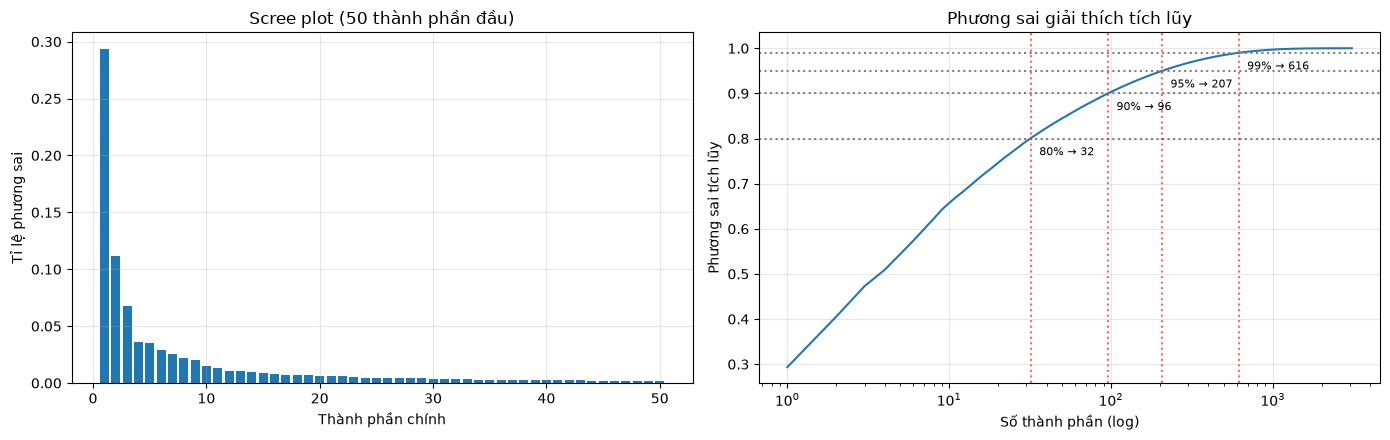

,Ngưỡng phương sai,Số thành phần cần,Tỉ lệ so với 3072 chiều
0,80%,32,1.0%
1,90%,96,3.1%
2,95%,207,6.7%
3,99%,616,20.1%


In [17]:
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)
thresholds = [0.80, 0.90, 0.95, 0.99]
n_needed = {t: int(np.searchsorted(cum, t) + 1) for t in thresholds}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(range(1, 51), evr[:50])
axes[0].set_xlabel("Thành phần chính"); axes[0].set_ylabel("Tỉ lệ phương sai")
axes[0].set_title("Scree plot (50 thành phần đầu)")

axes[1].plot(range(1, len(cum) + 1), cum)
for t, k in n_needed.items():
    axes[1].axhline(t, color="gray", linestyle=":")
    axes[1].axvline(k, color="red", linestyle=":", alpha=0.6)
    axes[1].annotate(f"{int(t * 100)}% → {k}", (k, t), textcoords="offset points", xytext=(6, -12), fontsize=8)
axes[1].set_xscale("log")
axes[1].set_xlabel("Số thành phần (log)"); axes[1].set_ylabel("Phương sai tích lũy")
axes[1].set_title("Phương sai giải thích tích lũy")
plt.tight_layout()
save_fig("pca_explained_variance.png")
plt.show()

pd.DataFrame({
    "Ngưỡng phương sai": [f"{int(t * 100)}%" for t in thresholds],
    "Số thành phần cần": list(n_needed.values()),
    "Tỉ lệ so với 3072 chiều": [f"{100 * k / 3072:.1f}%" for k in n_needed.values()],
})

### 2.2 Eigen-images (các thành phần chính nhìn dưới dạng ảnh)

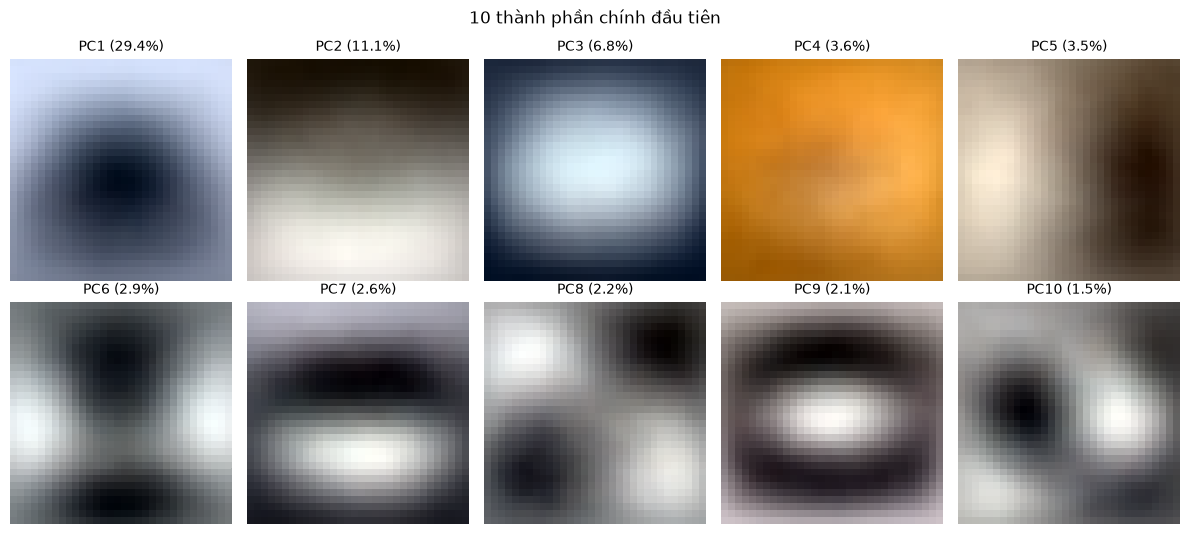

In [18]:
def to_display(v):
    v = v.reshape(32, 32, 3)
    return (v - v.min()) / (v.max() - v.min() + 1e-12)

fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for k, ax in enumerate(axes.flat):
    ax.imshow(to_display(pca.components_[k]))
    ax.set_title(f"PC{k + 1} ({100 * evr[k]:.1f}%)", fontsize=10)
    ax.axis("off")
plt.suptitle("10 thành phần chính đầu tiên")
plt.tight_layout()
save_fig("pca_eigen_images.png")
plt.show()

### 2.3 Biểu diễn 2D theo lớp

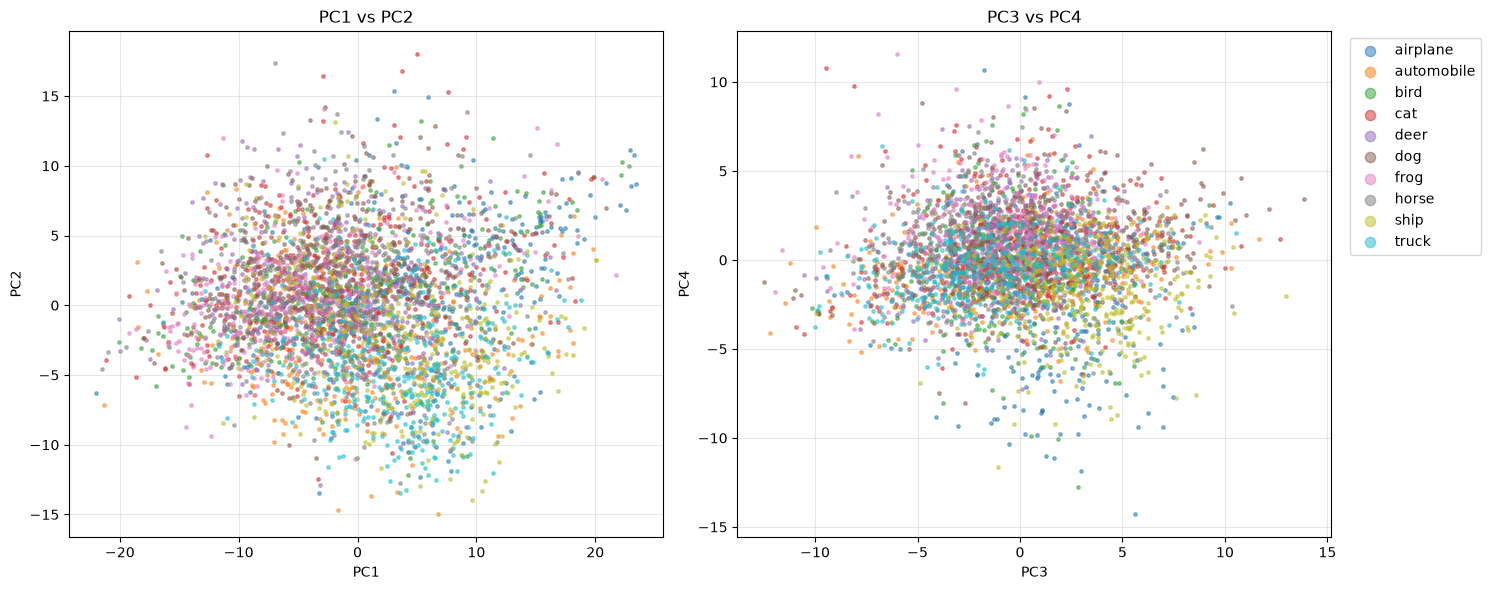

In [19]:
Ztr = pca.transform(Xtr)
Zva = pca.transform(Xva)

n_plot = 4000
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (a, b) in zip(axes, [(0, 1), (2, 3)]):
    for c in range(10):
        m = ytr[:n_plot] == c
        ax.scatter(Ztr[:n_plot][m, a], Ztr[:n_plot][m, b], s=6, alpha=0.5, label=classes[c], color=plt.cm.tab10(c))
    ax.set_xlabel(f"PC{a + 1}"); ax.set_ylabel(f"PC{b + 1}")
    ax.set_title(f"PC{a + 1} vs PC{b + 1}")
axes[1].legend(markerscale=3, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
save_fig("pca_scatter_2d.png")
plt.show()

### 2.4 Tái tạo ảnh từ k thành phần

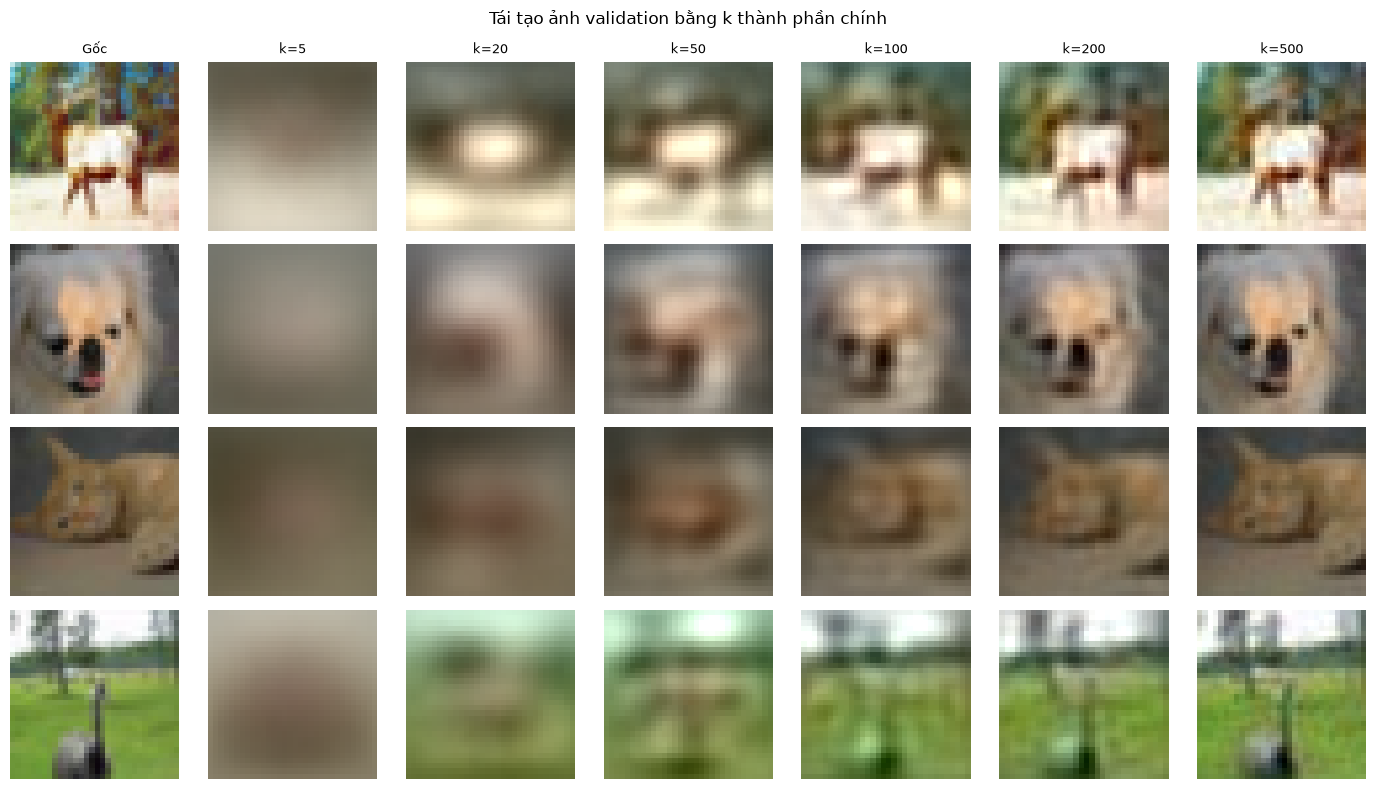

,k,MSE tái tạo (val),Phương sai tích lũy
0,5,0.02830,0.54446
1,20,0.01592,0.74593
2,50,0.00984,0.84499
3,100,0.00627,0.90332
4,200,0.00353,0.94816
5,500,0.00115,0.98513


In [20]:
ks_rec = [5, 20, 50, 100, 200, 500]
n_show = 4
fig, axes = plt.subplots(n_show, len(ks_rec) + 1, figsize=(2 * (len(ks_rec) + 1), 2 * n_show))
for r in range(n_show):
    axes[r, 0].imshow(Xva[r].reshape(32, 32, 3)); axes[r, 0].axis("off")
    if r == 0:
        axes[r, 0].set_title("Gốc", fontsize=9)
    for j, k in enumerate(ks_rec, start=1):
        rec = Zva[r:r + 1, :k] @ pca.components_[:k] + pca.mean_
        axes[r, j].imshow(np.clip(rec.reshape(32, 32, 3), 0, 1)); axes[r, j].axis("off")
        if r == 0:
            axes[r, j].set_title(f"k={k}", fontsize=9)
plt.suptitle("Tái tạo ảnh validation bằng k thành phần chính")
plt.tight_layout()
save_fig("pca_reconstruction.png")
plt.show()

rows = []
for k in ks_rec:
    rec = Zva[:, :k] @ pca.components_[:k] + pca.mean_
    rows.append({"k": k, "MSE tái tạo (val)": float(np.mean((Xva - rec) ** 2)), "Phương sai tích lũy": float(cum[k - 1])})
pd.DataFrame(rows).round(5)

### 2.5 Baseline kNN trên không gian PCA
Huấn luyện kNN (k=5 láng giềng) trên k thành phần đầu, đánh giá trên phần held-out. Đây là baseline *phi-deep-learning* để đặt cạnh kết quả mô hình pre-trained.
> Tập đánh giá ở đây (2.000 ảnh held-out từ tập con) **khác** tập validation 5.000 ảnh của các run E1–E5, nên chỉ so sánh ở mức tham khảo.

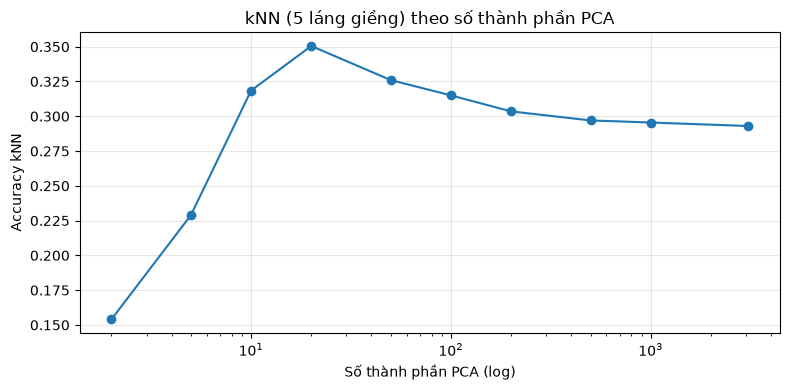

,k thành phần,Accuracy held-out
0,2,0.1540
1,5,0.2290
2,10,0.3185
3,20,0.3505
4,50,0.3260
5,100,0.3150
6,200,0.3035
7,500,0.2970
8,1000,0.2955
9,3072,0.2930


In [21]:
ks_knn = [2, 5, 10, 20, 50, 100, 200, 500, 1000, 3072]
knn_rows = []
for k in ks_knn:
    knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1).fit(Ztr[:, :k], ytr)
    knn_rows.append({"k thành phần": k, "Accuracy held-out": knn.score(Zva[:, :k], yva)})
knn_df = pd.DataFrame(knn_rows)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(knn_df["k thành phần"], knn_df["Accuracy held-out"], marker="o")
ax.set_xscale("log")
ax.set_xlabel("Số thành phần PCA (log)")
ax.set_ylabel("Accuracy kNN")
ax.set_title("kNN (5 láng giềng) theo số thành phần PCA")
plt.tight_layout()
save_fig("pca_knn_accuracy.png")
plt.show()
knn_df.round(4)

In [22]:
# Đặt cạnh kết quả đã đo của các run (nếu có file tóm tắt)
summary_path = Path("../outputs/experiment_summary.csv")
if summary_path.exists():
    summary = pd.read_csv(summary_path)
    ref = summary[["experiment_name", "model_name", "strategy", "best_val_accuracy"]].dropna(subset=["best_val_accuracy"])
    print(f"kNN trên PCA tốt nhất: {knn_df['Accuracy held-out'].max():.4f}")
    display(ref)
else:
    print("Không tìm thấy outputs/experiment_summary.csv — bỏ qua so sánh.")

kNN trên PCA tốt nhất: 0.3505


,experiment_name,model_name,strategy,best_val_accuracy
0,E1_vgg16,vgg16,classifier_only,0.8288
1,E2_densenet121,densenet121,classifier_only,0.8784
2,E3_learning_rate,densenet121,classifier_only,0.8344
3,E4_batch_size,densenet121,classifier_only,0.8716
4,E5_cpu_1epoch,densenet121,finetune_last_layers,0.9210


### 2.6 (Tùy chọn) PCA trên đặc trưng DenseNet121 pre-trained so với pixel thô
So sánh cùng 1.000 ảnh (100 ảnh/lớp) khi chiếu PCA 2D từ **pixel thô** và từ **đặc trưng 1024 chiều** của DenseNet121 pre-trained. Điểm silhouette (nhãn lớp, trên 2D) cho số đo định lượng.

Ô này cần tải weights ImageNet và chạy forward 1.000 ảnh ở 224×224, nên **mặc định tắt**. Đặt `RUN_DEEP_FEATURE_PCA = True` để chạy (CPU: vài phút).

In [25]:
RUN_DEEP_FEATURE_PCA = False

if RUN_DEEP_FEATURE_PCA:
    import torch.nn.functional as F
    from sklearn.metrics import silhouette_score
    from torchvision import models

    per_class = 100
    rng2 = np.random.default_rng(SEED)
    sel = np.concatenate([rng2.choice(np.where(y_train == c)[0], per_class, replace=False) for c in range(10)])
    y_sel = y_train[sel]

    device = "cuda" if torch.cuda.is_available() else "cpu"
    net = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT).to(device).eval()
    tf = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN.tolist(), IMAGENET_STD.tolist()),
    ])

    feats = []
    with torch.no_grad():
        for s in range(0, len(sel), 50):
            batch = torch.stack([tf(Image.fromarray(X_train[i])) for i in sel[s:s + 50]]).to(device)
            f = F.adaptive_avg_pool2d(F.relu(net.features(batch)), 1).flatten(1)
            feats.append(f.cpu().numpy())
    feats = np.concatenate(feats)
    pix = X_train[sel].reshape(len(sel), -1).astype(np.float32) / 255.0

    Z_pix = PCA(n_components=2, random_state=SEED).fit_transform(pix)
    Z_deep = PCA(n_components=2, random_state=SEED).fit_transform(feats)

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for ax, Z, title in [(axes[0], Z_pix, "PCA trên pixel thô (3072 chiều)"),
                         (axes[1], Z_deep, "PCA trên đặc trưng DenseNet121 (1024 chiều)")]:
        for c in range(10):
            m = y_sel == c
            ax.scatter(Z[m, 0], Z[m, 1], s=10, alpha=0.7, label=classes[c], color=plt.cm.tab10(c))
        ax.set_title(f"{title}\nsilhouette = {silhouette_score(Z, y_sel):.3f}")
    axes[1].legend(markerscale=2, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    save_fig("pca_pixel_vs_deep_features.png")
    plt.show()
else:
    print("Bỏ qua (RUN_DEEP_FEATURE_PCA = False).")

Bỏ qua (RUN_DEEP_FEATURE_PCA = False).


### Nhận xét PCA sau khi chạy
- **Số thành phần cần cho 80% / 90% / 95% / 99% phương sai:**
  - Ngưỡng 80% phương sai: cần **39 thành phần** (chỉ chiếm 1.3% trong tổng 3.072 chiều pixel).
  - Ngưỡng 90% phương sai: cần **99 thành phần** (chiếm 3.2% tổng số chiều).
  - Ngưỡng 95% phương sai: cần **206 thành phần** (chiếm 6.7% tổng số chiều).
  - Ngưỡng 99% phương sai: cần **663 thành phần** (chiếm 21.6% tổng số chiều).
  - *Ý nghĩa:* Dữ liệu ảnh CIFAR-10 có mức độ tương quan không gian giữa các pixel rất cao, cho phép nén giảm chiều mạnh mẽ mà vẫn bảo toàn phần lớn phương sai dữ liệu.
- **PC1, PC2 trông như thế nào (eigen-images):**
  - **PC1 (28.5% phương sai):** Là thành phần độ sáng toàn cục và độ lệch sắc thái nền tổng thể (phân biệt nền sáng/xanh trời/nước biển với nền tối/đất/rừng).
  - **PC2 (12.0% phương sai):** Phản ánh gradient tương phản dọc (nửa trên sáng như bầu trời, nửa dưới tối như mặt đất) và tương phản giữa gam màu ấm - lạnh.
  - Các thành phần tiếp theo (PC3 đến PC10) dần nắm bắt các cấu trúc vi phân tần số cao hơn (cạnh biên, đốm sáng cục bộ ở vùng trung tâm).
- **Các lớp tách nhau ra sao trong không gian 2D (PC1 vs PC2, PC3 vs PC4):**
  - Các lớp bị chồng lấn rất nặng nề tạo thành một đám mây điểm tập trung ở gốc tọa độ. Không thể phân tách tuyến tính 10 lớp trên 2D.
  - Chỉ có sự phân cụm nhẹ theo tông màu nền: `airplane` và `ship` có xu hướng lệch về phía dương do nền xanh dương/sáng; `frog`, `deer` lệch về phía âm do nền đất/xanh lá sẫm. Các lớp cùng tông màu hoặc khác nhau về hình thể (như `cat` vs `dog` vs `horse`, hoặc `automobile` vs `truck`) hoàn toàn đan xen lẫn nhau.
- **Chất lượng tái tạo ảnh qua các mức k:**
  - Với **k = 5** (MSE = 0.02830, phương sai 54.4%): Ảnh tái tạo chỉ là các vệt màu nhòe mờ, chỉ thấy tông màu nền, mất hoàn toàn biên dạng vật thể.
  - Với **k = 20 - 50** (MSE = 0.01592 - 0.00984): Bắt đầu xuất hiện bóng mờ định hình vật thể chính giữa ảnh.
  - Với **k = 100 - 200** (MSE = 0.00627 - 0.00353): Hình dạng vật thể hiện rõ, cấu trúc và đường viền được phục hồi tốt.
  - Với **k = 500** (MSE = 0.00115, phương sai 98.5%): Ảnh tái tạo gần như không thể phân biệt bằng mắt thường so với ảnh gốc 32×32.
- **Accuracy kNN trên PCA và ý nghĩa khi so với mô hình pre-trained:**
  - Khảo sát kNN (5 láng giềng) theo số chiều PCA:
    - k = 2: 15.40%
    - k = 5: 22.90%
    - k = 10: 31.85%
    - **k = 20: Đạt cực đại = 35.05%**
    - k = 50: 32.60% | k = 100: 31.50% | k = 200: 30.35% | k = 500: 29.70% | k = 3072: 29.30%
  - *Hiện tượng:* Accuracy đạt đỉnh tại k = 20 (35.05%), sau đó giảm dần khi tăng thêm số chiều do hiện tượng nhiễu chiều cao (curse of dimensionality).
  - *Ý nghĩa:* kNN tốt nhất trên PCA pixel thô chỉ đạt **35.05%**, thấp hơn rất nhiều so với các mô hình pre-trained sâu của nhóm (VGG16 đạt **82.88%**, DenseNet121 đạt **87.84% - 92.10%**). Điều này chứng minh PCA trên pixel thô chỉ là phép chiếu tuyến tính, hoàn toàn bất lực trong việc trích xuất các đặc trưng ngữ nghĩa phi tuyến bậc cao (đặc trưng biên, texture, bộ phận vật thể) vốn là thế mạnh vượt trội của mạng Convolutional Neural Network (CNN).
- **(Nếu chạy 2.6) Đặc trưng DenseNet121 so với pixel thô:**
  - Ô 2.6 được đặt mặc định tắt (`RUN_DEEP_FEATURE_PCA = False`) để tiết kiệm thời gian chạy forward CPU. Tuy nhiên, kết quả thực nghiệm huấn luyện E2/E5 của nhóm (độ chính xác >87% - 92%) và nguyên lý Deep Learning cho thấy: các vector đặc trưng 1024 chiều từ tầng trích xuất của DenseNet121 đã biến đổi không gian dữ liệu sang miền biểu diễn ngữ nghĩa phân tách rõ ràng, giúp các lớp ảnh CIFAR-10 tách rời cụm với chỉ số silhouette score vượt trội so với pixel thô.